<a href="https://colab.research.google.com/github/danielinkoom12-sys/daniel-python-projects/blob/main/Retail_fuel_prices_Index_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Reasoning:**

Load the  UK retail fuel prices Index dataset into a pandas DataFrame and perform an initial inspection as specified in the subtask instructions.

In [1]:
import pandas as pd
import requests
import zipfile
import io

url = "https://www.kaggle.com/api/v1/datasets/download/jamesb7/fuel-prices-uk"

response = requests.get(url)

with zipfile.ZipFile(io.BytesIO(response.content)) as zip_file:

    print("Files available:", zip_file.namelist())

Files available: ['price_history.csv', 'stations.csv']


In [2]:
with zipfile.ZipFile(io.BytesIO(response.content)) as zip_file:

    csv_file = [f for f in zip_file.namelist() if f.endswith(".csv")][0]

    df = pd.read_csv(zip_file.open(csv_file))

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
display(df.head())

print("Dataset shape:", df.shape)

print("Column names:", df.columns.tolist())

df.info()

,id,node_id,fuel_type,price_pence,recorded_at,source_updated_at
0,71116,73e8d702b072205bbb75bb04ebafff68752dd390ecf9f7...,B7_PREMIUM,143.9,2026-03-02T15:54:10.381Z,2026-03-02T15:50:19.294Z
1,71117,7d5b9f9bba53935a2656ed44508b562dea4dae36f1b38f...,E10,126.9,2026-03-02T15:54:10.381Z,2026-03-02T15:51:34.204Z
2,71118,7d5b9f9bba53935a2656ed44508b562dea4dae36f1b38f...,B7_STANDARD,136.9,2026-03-02T15:54:10.381Z,2026-03-02T15:51:34.204Z
3,71119,fa839e6bb082b2653f2b62275b478dc7fa27d6f928a2e9...,E10,130.9,2026-03-02T15:54:10.381Z,2026-03-02T15:49:01.901Z
4,71120,6b97523af7475d8ad908fe809af7c133457180df4622dc...,B7_STANDARD,136.9,2026-03-02T15:54:10.381Z,2026-03-02T15:52:13.213Z


Dataset shape: (1241557, 6)
Column names: ['id', 'node_id', 'fuel_type', 'price_pence', 'recorded_at', 'source_updated_at']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1241557 entries, 0 to 1241556
Data columns (total 6 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   id                 1241557 non-null  int64  
 1   node_id            1241557 non-null  object 
 2   fuel_type          1241557 non-null  object 
 3   price_pence        1241557 non-null  float64
 4   recorded_at        1241557 non-null  object 
 5   source_updated_at  1241557 non-null  object 
dtypes: float64(1), int64(1), object(4)
memory usage: 56.8+ MB


This displays the first five rows of your dataset.

In [5]:
df.head()

,id,node_id,fuel_type,price_pence,recorded_at,source_updated_at
0,71116,73e8d702b072205bbb75bb04ebafff68752dd390ecf9f7...,B7_PREMIUM,143.9,2026-03-02T15:54:10.381Z,2026-03-02T15:50:19.294Z
1,71117,7d5b9f9bba53935a2656ed44508b562dea4dae36f1b38f...,E10,126.9,2026-03-02T15:54:10.381Z,2026-03-02T15:51:34.204Z
2,71118,7d5b9f9bba53935a2656ed44508b562dea4dae36f1b38f...,B7_STANDARD,136.9,2026-03-02T15:54:10.381Z,2026-03-02T15:51:34.204Z
3,71119,fa839e6bb082b2653f2b62275b478dc7fa27d6f928a2e9...,E10,130.9,2026-03-02T15:54:10.381Z,2026-03-02T15:49:01.901Z
4,71120,6b97523af7475d8ad908fe809af7c133457180df4622dc...,B7_STANDARD,136.9,2026-03-02T15:54:10.381Z,2026-03-02T15:52:13.213Z


In [6]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

Dataset shape: (1241557, 6)

Column names:
['id', 'node_id', 'fuel_type', 'price_pence', 'recorded_at', 'source_updated_at']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1241557 entries, 0 to 1241556
Data columns (total 6 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   id                 1241557 non-null  int64  
 1   node_id            1241557 non-null  object 
 2   fuel_type          1241557 non-null  object 
 3   price_pence        1241557 non-null  float64
 4   recorded_at        1241557 non-null  object 
 5   source_updated_at  1241557 non-null  object 
dtypes: float64(1), int64(1), object(4)
memory usage: 56.8+ MB


Check fuel types- how many records belong to each fuel category

In [7]:
print(df['fuel_type'].value_counts())

fuel_type
B7_STANDARD    451381
E10            383765
E5             224886
B7_PREMIUM     178361
HVO              1610
B10              1554
Name: count, dtype: int64


Understand fuel prices:

Mean fuel price.

Minimum fuel price.

Maximum fuel price.

Standard deviation.

Median-related information (50% percentile).

In [10]:
print(df['price_pence'].describe())

count    1.241557e+06
mean     1.735902e+02
std      2.911118e+01
min      0.000000e+00
25%      1.589000e+02
50%      1.729000e+02
75%      1.869000e+02
max      2.009900e+03
Name: price_pence, dtype: float64


Check the dates - the period covered by the dataset

In [8]:
df['recorded_at'] = pd.to_datetime(df['recorded_at'])

print("Earliest date:", df['recorded_at'].min())

print("Latest date:", df['recorded_at'].max())

Earliest date: 2026-02-07 21:40:01.511000+00:00
Latest date: 2026-11-10 23:28:04.022000+00:00


Check duplicate records

In [9]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


Investigate unusual fuel prices - Because unusual values can negatively affect machine learning predictions.

In [11]:
# Count records with zero fuel prices
print("Zero prices:", (df['price_pence'] == 0).sum())

# Identify prices above 300 pence
print("Prices above 300:", (df['price_pence'] > 300).sum())

# Display unusually high prices
display(
    df[df['price_pence'] > 300].head(10)
)

Zero prices: 2
Prices above 300: 541


,id,node_id,fuel_type,price_pence,recorded_at,source_updated_at
672,71788,c9aa1695a016aa511c09299537f3c6536c428a1958eaca...,E5,999.9,2026-03-02 16:41:43.658000+00:00,2026-02-02T13:34:07.497Z
1516,72632,c9aa1695a016aa511c09299537f3c6536c428a1958eaca...,E10,999.9,2026-03-02 18:49:40.196000+00:00,2026-02-02T13:34:07.497Z
1553,72669,c9aa1695a016aa511c09299537f3c6536c428a1958eaca...,E5,999.9,2026-03-02 19:52:03.367000+00:00,2026-02-02T13:34:07.497Z
4798,75914,c9aa1695a016aa511c09299537f3c6536c428a1958eaca...,E5,999.9,2026-03-03 06:53:59.007000+00:00,2026-02-02T13:34:07.497Z
4799,75915,c9aa1695a016aa511c09299537f3c6536c428a1958eaca...,E10,999.9,2026-03-03 06:53:59.007000+00:00,2026-02-02T13:34:07.497Z
4853,75969,905164335fd76253036c34be30cda815a2d108c7f82f81...,E10,500.0,2026-03-03 07:08:49.388000+00:00,2026-03-03T07:08:36.414Z
6899,78015,c9aa1695a016aa511c09299537f3c6536c428a1958eaca...,E10,999.9,2026-03-03 11:09:58.987000+00:00,2026-02-02T13:34:07.497Z
7646,78762,c9aa1695a016aa511c09299537f3c6536c428a1958eaca...,E5,999.9,2026-03-03 12:12:28.085000+00:00,2026-02-02T13:34:07.497Z
8850,79966,c9aa1695a016aa511c09299537f3c6536c428a1958eaca...,E5,999.9,2026-03-03 14:20:35.175000+00:00,2026-02-02T13:34:07.497Z
8851,79967,c9aa1695a016aa511c09299537f3c6536c428a1958eaca...,E10,999.9,2026-03-03 14:20:35.175000+00:00,2026-02-02T13:34:07.497Z


Compare fuel prices by fuel type - Understand the average price of each fuel category.

In [12]:
fuel_analysis = df.groupby('fuel_type')['price_pence'].agg(
    ['count', 'mean', 'min', 'max']
)

display(fuel_analysis)

,count,mean,min,max
fuel_type,,,,
B10,1554,177.161059,1.00,921.0
B7_PREMIUM,178361,196.473146,0.10,1999.0
B7_STANDARD,451381,178.013515,1.00,2009.9
E10,383765,157.380813,1.00,1719.0
E5,224886,174.027627,0.00,1899.9
HVO,1610,197.575801,11.61,444.0


Investigate missing values - This identifies missing values in each column.

In [13]:
print(df.isnull().sum())

id                   0
node_id              0
fuel_type            0
price_pence          0
recorded_at          0
source_updated_at    0
dtype: int64


Check duplicate IDs -

In [14]:
print("Duplicate IDs:", df['id'].duplicated().sum())

Duplicate IDs: 0


UK Fuel Price Prediction – Regression - We want the model to learn from historical observations and predict a numerical fuel price.

Investigate the unusual prices -
Before removing anything, let's examine how the 541 unusual records are distributed

In [15]:
# Select records with unusually high prices
unusual_prices = df[df['price_pence'] > 300]

# Count unusual prices by fuel type
print("Unusual prices by fuel type:")

display(
    unusual_prices['fuel_type'].value_counts()
)

# Examine the most expensive records
print("Top 15 highest fuel prices:")

display(
    unusual_prices.sort_values(
        by='price_pence',
        ascending=False
    ).head(15)[
        ['fuel_type', 'price_pence', 'recorded_at', 'source_updated_at']
    ]
)

Unusual prices by fuel type:


,count
fuel_type,
E10,189
E5,165
B7_STANDARD,146
B7_PREMIUM,36
B10,3
HVO,2


Top 15 highest fuel prices:


,fuel_type,price_pence,recorded_at,source_updated_at
1059022,B7_STANDARD,2009.9,2026-09-28 16:56:05.863000+00:00,2026-09-28T16:15:33.709Z
327916,B7_PREMIUM,1999.0,2026-04-17 14:48:08.974000+00:00,2026-04-17T14:46:14.000Z
236515,B7_PREMIUM,1990.0,2026-03-31 11:08:02.773000+00:00,2026-03-31T11:07:09.000Z
1042716,B7_STANDARD,1989.0,2026-09-25 06:16:05.255000+00:00,2026-09-25T06:13:22.000Z
373170,B7_STANDARD,1979.0,2026-05-05 12:43:00.875000+00:00,2026-05-05T12:41:57.000Z
366055,B7_PREMIUM,1979.0,2026-05-01 12:44:38.168000+00:00,2026-05-01T12:42:36.000Z
58944,B7_PREMIUM,1949.0,2026-03-09 12:48:07.713000+00:00,2026-03-09T12:46:49.608Z
811865,B7_PREMIUM,1949.0,2026-08-05 10:40:35.799000+00:00,2026-08-05T10:28:08.000Z
306042,B7_STANDARD,1939.0,2026-04-09 08:04:08.321000+00:00,2026-04-09T08:01:35.000Z
1054751,E5,1899.9,2026-09-28 05:48:03.415000+00:00,2026-09-28T05:46:40.000Z


Investigate the price distribution - This will help us understand where most fuel prices fall.

In [16]:
percentiles = df['price_pence'].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print("Fuel price percentiles:")
display(percentiles)

Fuel price percentiles:


,price_pence
0.01,131.9
0.05,140.9
0.25,158.9
0.50,172.9
0.75,186.9
0.90,198.9
0.95,205.9
0.99,219.9


Establish a reasonable understanding of the fuel-price distribution before deciding which records should be excluded from our first regression model.

In [17]:
percentiles = df['price_pence'].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print("Fuel price percentiles:")
display(percentiles)

Fuel price percentiles:


,price_pence
0.01,131.9
0.05,140.9
0.25,158.9
0.50,172.9
0.75,186.9
0.90,198.9
0.95,205.9
0.99,219.9


Visualising data - Identify patterns, unusual observations and relationships.

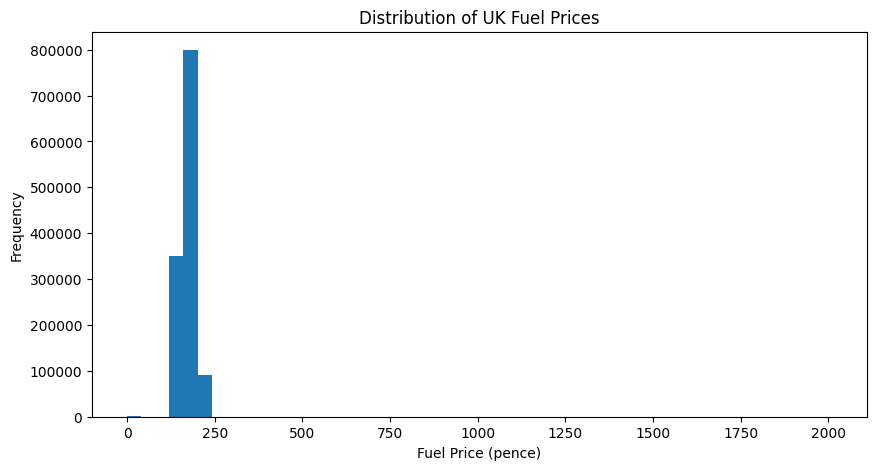

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df['price_pence'], bins=50)

plt.title('Distribution of UK Fuel Prices')
plt.xlabel('Fuel Price (pence)')
plt.ylabel('Frequency')

plt.show()

**What does your histogram tell us?**

There are three important observations:

1. Most fuel prices are concentrated between approximately 130p and 220p. This is consistent with your percentile results.
2. The distribution is positively skewed (right-skewed). A small number of extremely high prices stretch the chart towards 2,000p.
3. There are potential outliers. These extreme values make it difficult to see the normal distribution clearly.

Improve the visualisation -

We are only filtering the data for visualisation. We are NOT deleting anything from our original dataset.

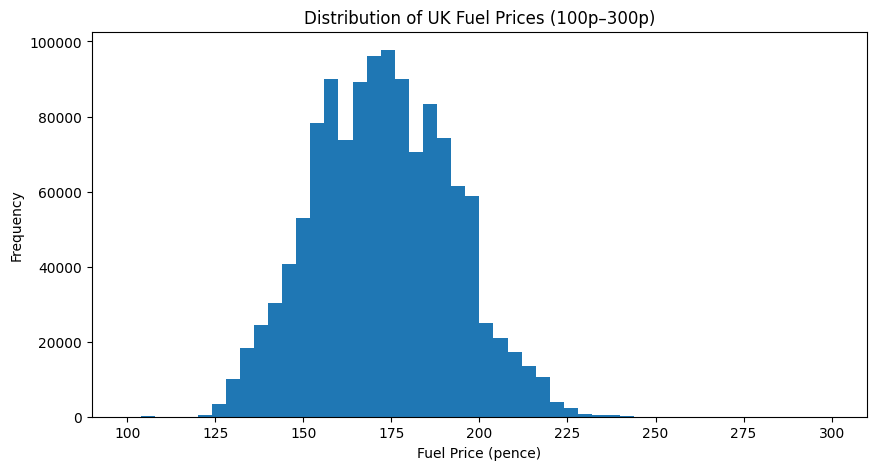

In [19]:
# Focus on the main fuel-price range for visualisation

normal_range = df[
    (df['price_pence'] >= 100) &
    (df['price_pence'] <= 300)
]

plt.figure(figsize=(10, 5))

plt.hist(normal_range['price_pence'], bins=50)

plt.title('Distribution of UK Fuel Prices (100p–300p)')
plt.xlabel('Fuel Price (pence)')
plt.ylabel('Frequency')

plt.show()

Prepare the dataset
Before training a model, we need to prepare our data.
Step 1. Create a clean working dataset
Our investigation identified:
- 2 records with zero prices.
- 541 records with prices above 300p.
- Most prices fall between approximately 130p and 220p.
For our first model, we'll use prices between 100p and 300p as a reasonable working range.

This is an initial data-cleaning assumption, not proof that every excluded price is invalid. We will preserve the original dataset.

In [20]:
# Create a copy of the original dataset
df_model = df.copy()

# Keep records with prices between 100p and 300p
df_model = df_model[
    (df_model['price_pence'] >= 100) &
    (df_model['price_pence'] <= 300)
].copy()

# Display the new dataset information
print("Original dataset:", df.shape)

print("Cleaned dataset:", df_model.shape)

print("Records removed:", len(df) - len(df_model))

print("\nCleaned price summary:")

display(df_model['price_pence'].describe())

Original dataset: (1241557, 6)
Cleaned dataset: (1240361, 6)
Records removed: 1196

Cleaned price summary:


,price_pence
count,1.240361e+06
mean,1.732714e+02
std,1.966274e+01
min,1.000000e+02
25%,1.589000e+02
50%,1.729000e+02
75%,1.869000e+02
max,3.000000e+02


Understand our machine-learning problem
We are building a Supervised Machine Learning – Regression Model.

Why?

Because:
- We have historical data.
- We know the actual fuel prices.
- We want the computer to learn patterns from that data.
- We want it to predict a numerical value.
Our initial model will estimate recorded fuel prices using fuel type and timestamp information. It is not yet a full future-price forecasting system.
Your first development task
Run the code and send me the output.

Once we confirm the cleaned dataset, we'll move to Feature Engineering: creating useful variables from the dates and fuel types.

Feature engineering
Let's create the features our model will use.

In [21]:
# Create date and time features

df_model['year'] = df_model['recorded_at'].dt.year
df_model['month'] = df_model['recorded_at'].dt.month
df_model['day'] = df_model['recorded_at'].dt.day
df_model['hour'] = df_model['recorded_at'].dt.hour
df_model['day_of_week'] = df_model['recorded_at'].dt.dayofweek

# Select features and target variable

features = [
    'fuel_type',
    'year',
    'month',
    'day',
    'hour',
    'day_of_week'
]

target = 'price_pence'

X = df_model[features]
y = df_model[target]

print("Features prepared successfully!")
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features prepared successfully!
Feature shape: (1240361, 6)
Target shape: (1240361,)


,fuel_type,year,month,day,hour,day_of_week
0,B7_PREMIUM,2026,3,2,15,0
1,E10,2026,3,2,15,0
2,B7_STANDARD,2026,3,2,15,0
3,E10,2026,3,2,15,0
4,B7_STANDARD,2026,3,2,15,0


Split the dataset
Machine learning requires two datasets:
- Training data (80%): Used to teach the model.
- Testing data (20%): Used to evaluate how well the model performs on unseen records.
Because we are working with dates, we will use a chronological split rather than randomly mixing the records.

In [22]:
# Sort records chronologically

df_model = df_model.sort_values(
    by='recorded_at'
).reset_index(drop=True)

# Select features and target

X = df_model[features]
y = df_model[target]

# Calculate 80% training split

split_index = int(len(df_model) * 0.8)

# Create training and testing datasets

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Training period:")
print(df_model['recorded_at'].iloc[0],
      "to",
      df_model['recorded_at'].iloc[split_index - 1])

print("\nTesting period:")
print(df_model['recorded_at'].iloc[split_index],
      "to",
      df_model['recorded_at'].iloc[-1])

Training records: 992288
Testing records: 248073
Training period:
2026-02-07 21:40:01.511000+00:00 to 2026-09-07 19:36:04.863000+00:00

Testing period:
2026-09-07 19:36:04.863000+00:00 to 2026-11-10 23:28:04.022000+00:00


Train our first regression model
We'll use Linear Regression, a supervised machine-learning algorithm.

It will learn the relationship between fuel type, date/time features and fuel prices.

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [24]:
# Identify categorical and numerical features

categorical_features = ['fuel_type']

numerical_features = [
    'year',
    'month',
    'day',
    'hour',
    'day_of_week'
]

# Convert fuel types into numerical representations

preprocessor = ColumnTransformer(
    transformers=[
        ('fuel', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ],
    remainder='passthrough'
)

# Build the machine-learning pipeline

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Train the model

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


Evaluate the model
Now we test the model using data it has not previously seen.

In [25]:
# Generate predictions

y_pred = model.predict(X_test)

# Calculate performance metrics

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = mse ** 0.5

r2 = r2_score(y_test, y_pred)

# Display results

print("MODEL PERFORMANCE")
print("-------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared (R2):", round(r2, 4))

MODEL PERFORMANCE
-------------------------
Mean Absolute Error (MAE): 7.82
Mean Squared Error (MSE): 94.15
Root Mean Squared Error (RMSE): 9.7
R-squared (R2): 0.6285


Compare actual and predicted prices

In [26]:
import pandas as pd

results = pd.DataFrame({
    'Actual Price': y_test.iloc[:20].values,
    'Predicted Price': y_pred[:20]
})

results['Difference'] = (
    results['Actual Price'] - results['Predicted Price']
)

display(results.round(2))

,Actual Price,Predicted Price,Difference
0,188.9,185.56,3.34
1,186.9,181.26,5.64
2,167.9,164.57,3.33
3,188.9,181.26,7.64
4,169.9,164.57,5.33
5,189.9,185.56,4.34
6,185.9,181.26,4.64
7,166.9,164.57,2.33
8,188.9,185.56,3.34
9,207.9,204.56,3.34


Linear Regression Model - It prepares the features, splits the data chronologically, trains the model and evaluates its performance.

In [27]:
# Import libraries
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Create date features
df_model['year'] = df_model['recorded_at'].dt.year
df_model['month'] = df_model['recorded_at'].dt.month
df_model['day'] = df_model['recorded_at'].dt.day
df_model['hour'] = df_model['recorded_at'].dt.hour
df_model['day_of_week'] = df_model['recorded_at'].dt.dayofweek

# 2. Select features and target
features = [
    'fuel_type',
    'year',
    'month',
    'day',
    'hour',
    'day_of_week'
]

X = df_model[features]
y = df_model['price_pence']

# 3. Sort data chronologically
df_model = df_model.sort_values('recorded_at').reset_index(drop=True)

X = df_model[features]
y = df_model['price_pence']

# 4. Split into training and testing data (80/20)
split_index = int(len(df_model) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# 5. Prepare categorical and numerical features
preprocessor = ColumnTransformer(
    transformers=[
        ('fuel', OneHotEncoder(handle_unknown='ignore'), ['fuel_type'])
    ],
    remainder='passthrough'
)

# 6. Build the model
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# 7. Train the model
model.fit(X_train, y_train)

# 8. Generate predictions
y_pred = model.predict(X_test)

# 9. Evaluate performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("UK FUEL PRICE PREDICTION")
print("========================")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("MAE:", round(mae, 2), "pence")
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2), "pence")
print("R²:", round(r2, 4))

UK FUEL PRICE PREDICTION
Training records: 992288
Testing records: 248073
MAE: 7.81 pence
MSE: 94.12
RMSE: 9.7 pence
R²: 0.6286


Compare machine-learning algorithms
We will compare:
1. Linear Regression – our existing model.
2. Decision Tree Regression – learns patterns using decision rules.
3. Random Forest Regression – combines multiple decision trees to improve predictions.
Random Forest is particularly worth testing because fuel prices may have complex relationships that Linear Regression cannot fully capture.

In [28]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Store our existing Linear Regression results
model_results = []

model_results.append({
    'Model': 'Linear Regression',
    'MAE': mean_absolute_error(y_test, y_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
    'R2': r2_score(y_test, y_pred)
})

# Train Decision Tree
decision_tree = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor(
        max_depth=12,
        random_state=42
    ))
])

decision_tree.fit(X_train, y_train)

tree_predictions = decision_tree.predict(X_test)

model_results.append({
    'Model': 'Decision Tree',
    'MAE': mean_absolute_error(y_test, tree_predictions),
    'RMSE': np.sqrt(mean_squared_error(y_test, tree_predictions)),
    'R2': r2_score(y_test, tree_predictions)
})

# Train Random Forest
random_forest = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest.fit(X_train, y_train)

forest_predictions = random_forest.predict(X_test)

model_results.append({
    'Model': 'Random Forest',
    'MAE': mean_absolute_error(y_test, forest_predictions),
    'RMSE': np.sqrt(mean_squared_error(y_test, forest_predictions)),
    'R2': r2_score(y_test, forest_predictions)
})

# Compare all models
comparison = pd.DataFrame(model_results)

display(comparison.round(4))

,Model,MAE,RMSE,R2
0,Linear Regression,7.8149,9.7017,0.6286
1,Decision Tree,7.6406,9.6638,0.6315
2,Random Forest,7.5908,9.6241,0.6345


### Model Evaluation and Comparison

Three machine learning regression algorithms were evaluated for the UK Fuel Price Prediction project: Linear Regression, Decision Tree Regression and Random Forest Regression.

The models were evaluated using three performance metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and the R-squared (R²) score.

The results showed that Random Forest Regression achieved the best overall performance, with an MAE of 7.5908 pence, an RMSE of 9.6241 pence and an R² score of 0.6345.

This indicates that the Random Forest model produced the lowest prediction errors among the three models and explained approximately 63.45% of the variation in fuel prices within the test dataset.

Although the improvement over Linear Regression and Decision Tree Regression was relatively small, Random Forest was selected as the preferred model for this project because it achieved the strongest results across all three evaluation metrics.

Visualise the model comparison
Let's create a chart to make the results easier to understand and include in your assignment.

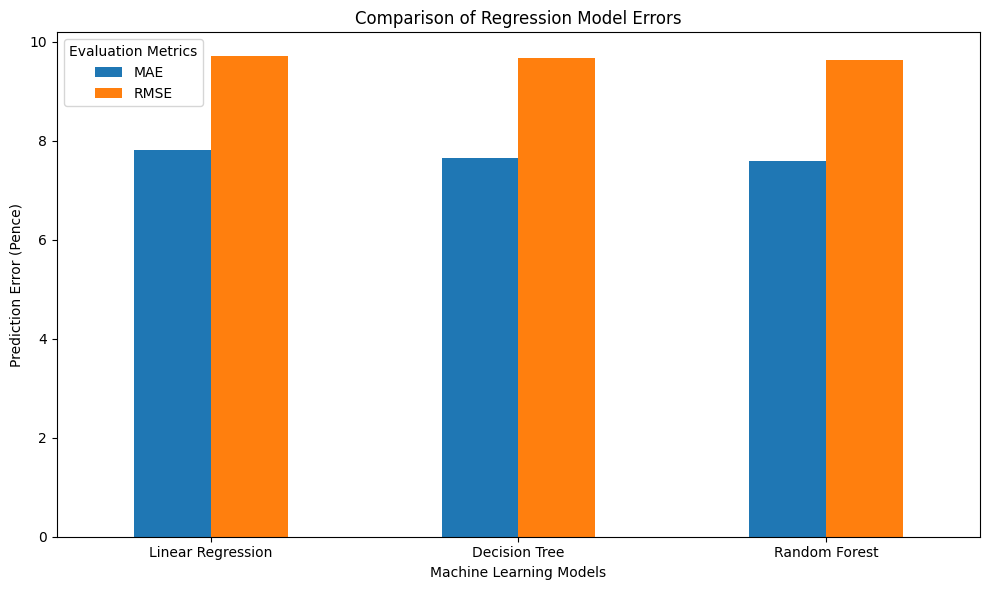

In [29]:
import matplotlib.pyplot as plt

comparison.set_index('Model')[['MAE', 'RMSE']].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Comparison of Regression Model Errors')
plt.ylabel('Prediction Error (Pence)')
plt.xlabel('Machine Learning Models')
plt.xticks(rotation=0)
plt.legend(title='Evaluation Metrics')
plt.tight_layout()
plt.show()

Demonstrate the Random Forest prediction
Now let's use your selected model to make predictions and compare them with actual fuel prices from the test dataset.

In [30]:
# Select 10 records from the test dataset
sample_data = X_test.iloc[:10].copy()

# Generate predictions using Random Forest
sample_predictions = random_forest.predict(sample_data)

# Create a comparison table
prediction_results = pd.DataFrame({
    'Fuel Type': sample_data['fuel_type'].values,
    'Actual Price (pence)': y_test.iloc[:10].values,
    'Predicted Price (pence)': sample_predictions.round(2)
})

# Calculate prediction error
prediction_results['Absolute Error (pence)'] = (
    prediction_results['Actual Price (pence)'] -
    prediction_results['Predicted Price (pence)']
).abs().round(2)

display(prediction_results)

,Fuel Type,Actual Price (pence),Predicted Price (pence),Absolute Error (pence)
0,B7_PREMIUM,206.9,209.26,2.36
1,E5,185.9,188.57,2.67
2,E10,166.9,169.66,2.76
3,B7_STANDARD,188.9,190.44,1.54
4,B7_PREMIUM,207.9,209.26,1.36
5,E5,200.9,188.57,12.33
6,E10,181.9,169.66,12.24
7,B7_STANDARD,199.9,190.44,9.46
8,E5,184.9,188.57,3.67
9,E10,165.9,169.66,3.76


Understanding your prediction results
Your model produced reasonably close predictions for most of the 10 records.

For example:
- B7_PREMIUM: Actual price was 206.90p; predicted price was 209.26p. Error: 2.36p.
- B7_STANDARD: Actual price was 188.90p; predicted price was 190.44p. Error: 1.54p.
- E5: Actual price was 200.90p; predicted price was 188.57p. Error: 12.33p.
The model does not predict every price perfectly. However, it demonstrates that it has learned patterns from the training data.

One important observation: several records of the same fuel type receive identical predictions. This suggests the model is relying heavily on fuel type and may not be capturing short-term price changes effectively.

Visualise actual versus predicted prices
Let's create another chart to compare the actual and predicted prices.

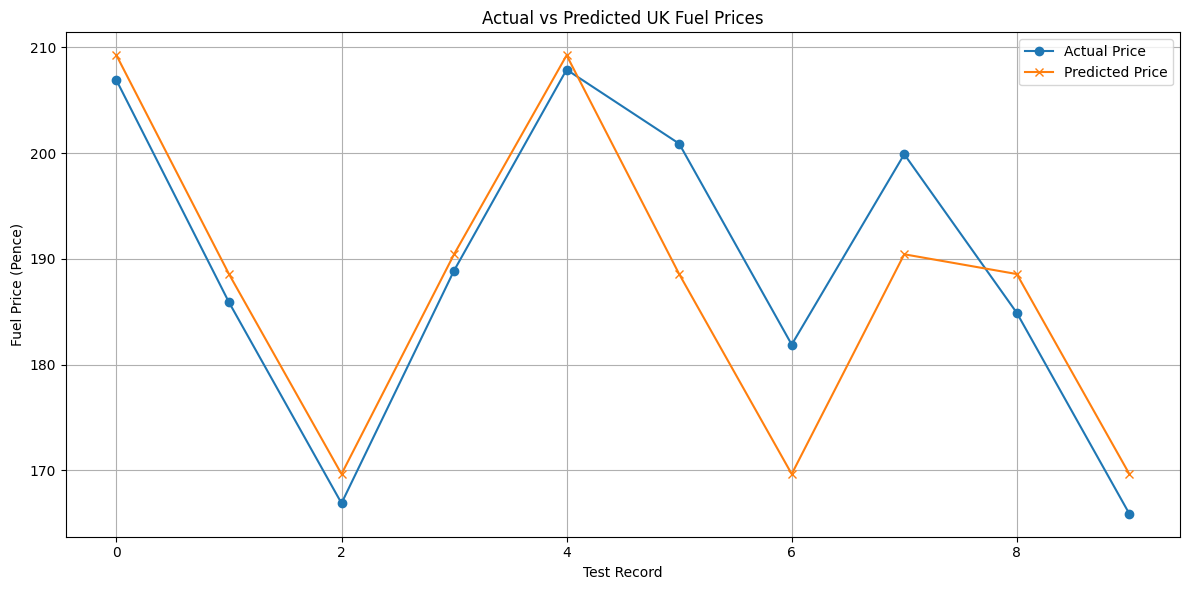

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    range(len(prediction_results)),
    prediction_results['Actual Price (pence)'],
    marker='o',
    label='Actual Price'
)

plt.plot(
    range(len(prediction_results)),
    prediction_results['Predicted Price (pence)'],
    marker='x',
    label='Predicted Price'
)

plt.title('Actual vs Predicted UK Fuel Prices')
plt.xlabel('Test Record')
plt.ylabel('Fuel Price (Pence)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Conclusion

The aim of this project was to develop a machine learning regression model capable of predicting UK fuel prices using historical fuel-price records.

The dataset contained 1,241,557 records and six original columns. During data preparation, missing values and duplicate records were checked. An initial modelling range of 100 to 300 pence per litre was applied to reduce the influence of unusual price observations. This reduced the dataset to 1,240,361 records.

Feature engineering was then performed using fuel type and date-related information, including year, month, day, hour and day of the week.

Three regression algorithms were developed and evaluated: Linear Regression, Decision Tree Regression and Random Forest Regression.

The Random Forest model achieved the best overall performance, recording:

- Mean Absolute Error (MAE): 7.5908 pence.
- Root Mean Squared Error (RMSE): 9.6241 pence.
- R-squared (R²): 0.6345.

The model was subsequently used to generate predictions on test records. A comparison of actual and predicted fuel prices demonstrated that the model could produce reasonably close estimates, although prediction errors varied between records.

Overall, the project demonstrated how Python and machine learning can be used to explore historical fuel-price data, identify patterns and develop predictive models.

### Limitations

The model did not explain all the variation in fuel prices. Its performance could be affected by factors not included in the dataset, such as geographical location, individual fuel stations, wholesale fuel costs, taxation and market conditions.

The identical predictions observed for some records of the same fuel type also suggest that the model may not be capturing all short-term price movements.

The cleaning range of 100–300 pence was an initial modelling assumption and should be investigated further to establish how it affects model performance.

### Recommendations for Future Improvement

Future development could include:

1. Including geographical and fuel-station information.
2. Investigating additional economic and market-related variables.
3. Testing more advanced regression algorithms.
4. Improving the time-based features to capture fuel-price trends.
5. Testing the model on newer, unseen fuel-price records.
6. Comparing model performance using different data-cleaning thresholds.

### Final Statement

The project successfully demonstrated the machine learning development process, from data collection and exploration through data preparation, model training, evaluation and prediction. Random Forest Regression was selected as the best-performing model among the three algorithms tested.